<a href="https://colab.research.google.com/github/jlredding/Clipboard_Health_Dashboard/blob/main/Clipboard_Health.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nursing Home Staffing Analysis: Q2 2024
**Data Engineer Academy · Healthcare Metrics Project** · Jon Redding

Analysis of the CMS Payroll Based Journal (PBJ) Daily Nurse Staffing data for April through June 2024: 1.3 million daily staffing records from 14,564 U.S. nursing homes.

**🔗 Interactive dashboard:** [clipboard-health-staffing.streamlit.app](https://clipboard-health-staffing.streamlit.app/) · **Code:** [Clipboard_Health_Dashboard](https://github.com/jlredding/Clipboard_Health_Dashboard)

### Key findings
- Nursing homes provided **3.30 nursing hours per resident day (HPRD)** nationally, but **34.5% of facilities** averaged below 3.0 for the quarter.
- **Missouri (2.42), Texas (2.68), Oklahoma (2.80), Indiana (2.82) and New Mexico (2.84)** are the only states below 3.0. In each, roughly 70–80% of facilities fall below it.
- **Facility size barely predicts staffing per resident** (r = −0.12). The strong census-vs-total-hours correlation (r = 0.91) mostly reflects size.
- Contract (agency) staff provide **7.7% of nursing hours**; **43.6% of facilities use none**. **Vermont is the outlier at 32%.**
- Contract use is only **weakly associated** with higher staffing (r = 0.21 across states, 0.02 across facilities).
- **20 facilities** report almost no nursing hours for the entire quarter: missing data, not real staffing levels.

---
## Assignment brief
*The brief below is the original project prompt. It refers to "hospitals," but PBJ data covers **nursing homes** (skilled nursing facilities), so this analysis says "facility" or "nursing home" throughout.*

---
**Data Engineer Academy**

Healthcare Metrics Project


---


**1. Project Objective**

The goal of this project is to analyze hospital staffing and operational performance using nurse staffing data. The analysis will help understand how nurse availability, workload, and patient volumes affect care quality and operational efficiency.

The final output will be an analytical dashboard that helps management:

- Understand nurse-to-patient ratios
- Monitor staffing levels across hospitals and states
- Identify overtime trends
- Compare staffing levels with patient load
- Detect facilities with potential staffing shortages


---


**2. Data Overview**

- Primary dataset: PBJ_Daily_Nurse_Staffing_Q2_2024.csv
    
- Each record represents daily staffing activity for a healthcare provider (hospital).

**Important Columns:**

- PROVNUM – Unique hospital/provider identifier
  
- PROVNAME – Hospital name

- CITY – City location

- STATE – State location

- COUNTY_NAME – County name

- WorkDate – Date of staffing record

- MDScensus – Number of patients present (patient census)


**Staffing Hour Columns:**

- Registered Nurses (RN)

- Hrs_RN – Total RN hours

- Hrs_RN_emp – RN hours worked by employed staff

- Hrs_RN_ctr – RN hours worked by contracted staff

- Licensed Practical Nurses (LPN)

- Hrs_LPN – Total LPN hours

- Hrs_LPN_emp – Employed LPN hours

- Hrs_LPN_ctr – Contracted LPN hours

**Certified Nursing Assistants (CNA)**

- Hrs_CNA – Total CNA hours

- Hrs_CNA_emp – Employed CNA hours

- Hrs_CNA_ctr – Contracted CNA hours

**Other Staff**

- Hrs_NAtrn – Nursing assistants in training

- Hrs_MedAide – Medication aide hours


---


**3. Data Analysis Tasks**

Before building metrics, perform exploratory data analysis (EDA).

**Tasks:**

• Understand the dataset structure and schema

• Identify key columns for grouping and analysis

• Check for missing values

• Identify duplicate records
• Detect outliers in staffing hours
• Convert date fields to proper datetime format


---


**4. Data Cleaning**

Perform the following cleaning steps:
• Handle missing values where appropriate
• Remove duplicate rows
• Ensure WorkDate is in datetime format
• Verify that staffing hours are numeric
• Check unrealistic staffing values (extreme outliers)
• Create derived columns for total nurse hours


---


**5. Key Metrics to Calculate**

You must select 3–5 metrics that can be calculated from the dataset.

Recommended metrics:
1. Nurse-to-Patient Ratio
Formula:
(Total RN + LPN + CNA Hours) / Patient Census
This measures staffing coverage relative to patient load.

2. Total Nurse Hours
Total nurse hours worked per hospital per month.
Group by:
• Hospital
• State
• Month

3. Contract vs Permanent Staff Ratio
Formula:
Contract Staff Hours / Total Nurse Hours
Helps understand reliance on temporary staff.

4. Average Patient Census
Average number of patients per hospital or per state.

5. Hospitals with Highest Staffing Hours
Identify hospitals with the highest total staffing hours.


---


**6. Analytical Questions**

The analysis should answer the following questions:

1. What is the relationship between nurse staffing levels and patient census?

2. Which hospitals have the highest staffing hours?

3. What are the average staffing levels by state?

4. Which facilities have the lowest nurse-to-patient coverage?

5. Are certain states relying more on contract nurses?


---


**7. Visualization Dashboard**

Create an interactive dashboard using Streamlit or a BI tool.

Recommended Visualizations:

- Staffing Overview

  - Nurse hours by hospital

  - Staffing comparison by state

  - Contract vs employed staff ratio

  - Patient Load
    - Patient census trends
    - Nurse-to-patient ratio trends

  - Operational Insights
    - Top 10 busiest hospitals
    - Facilities with lowest staffing coverage


---


**8. Final Deliverables**

The final submission should include:
- Cleaned dataset or transformation scripts
- SQL queries or Python analysis code
- Data dictionary explaining columns
- Analytical dashboard
- Short presentation or documentation explaining insights

Also explain the reasoning behind each metric and visualization.



---
## 1. Setup and data loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# Load from Google Drive when running in Colab; otherwise look in the current folder
try:
    from google.colab import drive
    drive.mount("/content/drive")
    file_path = "/content/drive/MyDrive/Colab Notebooks/Clipboard Health/PBJ_Daily_Nurse_Staffing_Q2_2024.csv"
except ImportError:
    file_path = "PBJ_Daily_Nurse_Staffing_Q2_2024.csv"

TARGET_HPRD = 3.0   # analysis reference line (not a regulatory standard)
STRAIN_HPRD = 1.5   # daily level treated as possible strain
GAP_HPRD = 0.5      # quarter-wide HPRD below this = almost certainly missing payroll data

In [ ]:
# PROVNUM is read as text: some provider numbers contain letters, and leading zeros matter
df = pd.read_csv(file_path, encoding="cp1252", dtype={"PROVNUM": str}, low_memory=False)

print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
print(f"Facilities (PROVNUM): {df['PROVNUM'].nunique():,} | States/territories: {df['STATE'].nunique()}")
df.head()

Rows: 1,325,324 | Columns: 33
Facilities (PROVNUM): 14,564 | States/territories: 52


,PROVNUM,PROVNAME,CITY,STATE,COUNTY_NAME,COUNTY_FIPS,CY_Qtr,WorkDate,MDScensus,Hrs_RNDON,Hrs_RNDON_emp,Hrs_RNDON_ctr,Hrs_RNadmin,Hrs_RNadmin_emp,Hrs_RNadmin_ctr,Hrs_RN,Hrs_RN_emp,Hrs_RN_ctr,Hrs_LPNadmin,Hrs_LPNadmin_emp,Hrs_LPNadmin_ctr,Hrs_LPN,Hrs_LPN_emp,Hrs_LPN_ctr,Hrs_CNA,Hrs_CNA_emp,Hrs_CNA_ctr,Hrs_NAtrn,Hrs_NAtrn_emp,Hrs_NAtrn_ctr,Hrs_MedAide,Hrs_MedAide_emp,Hrs_MedAide_ctr
0,015009,"BURNS NURSING HOME, INC.",RUSSELLVILLE,AL,Franklin,59,2024Q2,20240401,51,10.77,10.77,0.0,10.40,10.40,0.0,55.70,55.70,0.0,0.0,0.0,0.0,25.50,25.50,0.0,160.08,160.08,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,015009,"BURNS NURSING HOME, INC.",RUSSELLVILLE,AL,Franklin,59,2024Q2,20240402,52,8.43,8.43,0.0,18.25,18.25,0.0,63.28,63.28,0.0,0.0,0.0,0.0,15.22,15.22,0.0,135.95,135.95,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,015009,"BURNS NURSING HOME, INC.",RUSSELLVILLE,AL,Franklin,59,2024Q2,20240403,53,11.13,11.13,0.0,12.08,12.08,0.0,76.29,76.29,0.0,0.0,0.0,0.0,5.46,5.46,0.0,150.31,150.31,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,015009,"BURNS NURSING HOME, INC.",RUSSELLVILLE,AL,Franklin,59,2024Q2,20240404,52,12.27,12.27,0.0,17.53,17.53,0.0,54.13,54.13,0.0,0.0,0.0,0.0,20.18,20.18,0.0,133.01,133.01,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,015009,"BURNS NURSING HOME, INC.",RUSSELLVILLE,AL,Franklin,59,2024Q2,20240405,52,4.95,4.95,0.0,17.42,17.42,0.0,53.63,53.63,0.0,0.0,0.0,0.0,27.85,27.85,0.0,137.92,137.92,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Why the CSV and not an Excel export:** an earlier version of this analysis loaded an `.xlsx` copy of the data. Excel stops at **1,048,575 rows**, and because the file is sorted by state, that silently dropped the last ~277,000 rows: **Texas, Utah, Virginia, Vermont, Washington, Wisconsin, West Virginia and Wyoming** were missing entirely. Loading the source CSV restores all 1,325,324 rows and 52 states/territories.

*Lesson: always check row and category counts against the source after loading.*

---
## 2. Data quality checks
Structure, missing values, duplicates, data types and implausible values.

In [ ]:
df.info()
print("\nMissing values in any column:", int(df.isnull().sum().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 1325324 entries, 0 to 1325323
Data columns (total 33 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   PROVNUM           1325324 non-null  str    
 1   PROVNAME          1325324 non-null  str    
 2   CITY              1325324 non-null  str    
 3   STATE             1325324 non-null  str    
 4   COUNTY_NAME       1325324 non-null  str    
 5   COUNTY_FIPS       1325324 non-null  int64  
 6   CY_Qtr            1325324 non-null  str    
 7   WorkDate          1325324 non-null  int64  
 8   MDScensus         1325324 non-null  int64  
 9   Hrs_RNDON         1325324 non-null  float64
 10  Hrs_RNDON_emp     1325324 non-null  float64
 11  Hrs_RNDON_ctr     1325324 non-null  float64
 12  Hrs_RNadmin       1325324 non-null  float64
 13  Hrs_RNadmin_emp   1325324 non-null  float64
 14  Hrs_RNadmin_ctr   1325324 non-null  float64
 15  Hrs_RN            1325324 non-null  float64
 16  Hrs_RN_emp 

There are **no missing values** in any of the 33 columns. Identifier and location fields are text, `WorkDate` is stored as an integer (e.g. `20240401`) and needs converting, and all hour and census fields are numeric.

In [ ]:
key_cols = ["MDScensus", "Hrs_RN", "Hrs_LPN", "Hrs_CNA", "Hrs_RN_ctr", "Hrs_LPN_ctr", "Hrs_CNA_ctr", "Hrs_RNDON"]
df[key_cols].describe().round(2)

,MDScensus,Hrs_RN,Hrs_LPN,Hrs_CNA,Hrs_RN_ctr,Hrs_LPN_ctr,Hrs_CNA_ctr,Hrs_RNDON
count,1325324.00,1325324.00,1325324.00,1325324.00,1325324.00,1325324.00,1325324.00,1325324.00
mean,83.42,34.80,66.17,173.79,2.81,6.13,12.18,5.20
std,49.04,35.32,49.82,115.16,10.50,19.64,31.84,4.39
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,51.00,13.25,32.60,98.57,0.00,0.00,0.00,0.00
50%,76.00,25.75,56.81,150.62,0.00,0.00,0.00,8.00
75%,104.00,45.25,88.50,220.00,0.00,4.00,8.00,8.00
max,742.00,915.98,13946.25,1758.10,512.39,13801.50,661.42,103.96


In [ ]:
print("Unique values per key column:")
print(df[["PROVNUM", "PROVNAME", "STATE", "WorkDate", "CY_Qtr"]].nunique())

exact_dupes = df.duplicated().sum()
key_dupes = df.duplicated(subset=["PROVNUM", "WorkDate"]).sum()
print(f"\nExact duplicate rows: {exact_dupes}")
print(f"Duplicate facility-day records (PROVNUM + WorkDate): {key_dupes}")

# Facility names are not unique identifiers: different facilities share a name
shared = df.groupby("PROVNAME")["PROVNUM"].nunique()
print(f"Facility names used by more than one provider number: {(shared > 1).sum()}")

Unique values per key column:
PROVNUM     14564
PROVNAME    14378
STATE          52
WorkDate       91
CY_Qtr          1
dtype: int64



Exact duplicate rows: 0
Duplicate facility-day records (PROVNUM + WorkDate): 0
Facility names used by more than one provider number: 150


- **14,564 facilities** across **all 50 states plus DC and Puerto Rico**, and **91 days**, which is exactly one quarter.
- **No duplicate rows** and no duplicate facility-day records.
- **Facility names are not unique.** 150 names belong to more than one provider number (chains such as "Miller's Merry Manor" operate a dozen separate facilities under the same name). All grouping below uses `PROVNUM`, the unique CMS provider ID.

In [ ]:
df["WorkDate"] = pd.to_datetime(df["WorkDate"].astype(str), format="%Y%m%d")
print(df["WorkDate"].min().date(), "to", df["WorkDate"].max().date(), "|", df["WorkDate"].nunique(), "days")

2024-04-01 to 2024-06-30 | 91 days


In [ ]:
hour_cols = [c for c in df.columns if c.startswith("Hrs_")]
print("All hour columns numeric:", all(pd.api.types.is_numeric_dtype(df[c]) for c in hour_cols))
print("Negative values in any hour column:", int((df[hour_cols] < 0).sum().sum()))

# A whole facility can log far more than 24 hours a day (many staff), so check hours PER RESIDENT instead
direct = df["Hrs_RN"] + df["Hrs_LPN"] + df["Hrs_CNA"]
per_res = direct / df["MDScensus"].where(df["MDScensus"] > 0)
print(f"Facility-days with more than 24 direct-care hours per resident: {(per_res > 24).sum():,}")

All hour columns numeric: True
Negative values in any hour column: 0
Facility-days with more than 24 direct-care hours per resident: 55


**Range check note:** a facility's *total* daily hours routinely exceed 24, since a 100-resident home may log 300+ nursing hours a day across many staff. So the plausibility check is done **per resident**: only 55 facility-days exceed 24 direct-care hours per resident.

In [ ]:
print(f"Rows with negative census: {(df['MDScensus'] < 0).sum()}")
print(f"Rows with zero census: {(df['MDScensus'] == 0).sum()}")
print(f"Rows where Director of Nursing hours exceed 24 in one day: {(df['Hrs_RNDON'] > 24).sum():,}")

Rows with negative census: 0
Rows with zero census: 320
Rows where Director of Nursing hours exceed 24 in one day: 1,131


**Anomalies found:**
- **0 negative census values.**
- **320 rows with zero residents.** These can't produce a per-resident measure (division by zero), so they're removed.
- **1,131 rows where the Director of Nursing logged more than 24 hours in one day.** The DON is a single person, so these are reporting errors; they're capped at 24. (DON hours aren't part of the direct-care total used below, so this doesn't affect the main metrics.)

In [ ]:
start = len(df)
df = df[df["MDScensus"] > 0].copy()                      # avoid dividing by zero residents
print(f"Removed {start - len(df)} zero-census rows -> {len(df):,} rows remain")

over = df["Hrs_RNDON"] > 24
df.loc[over, "Hrs_RNDON"] = 24.0                          # one DON cannot work more than 24 hours a day
print(f"Capped Director of Nursing hours at 24 on {over.sum():,} rows")

Removed 320 zero-census rows -> 1,325,004 rows remain
Capped Director of Nursing hours at 24 on 1,131 rows


---
## 3. Derived columns
- `Total_Nurse_Hours` = RN + LPN + CNA hours (direct care)
- `Total_Contract_Hours` = contract RN + LPN + CNA hours
- `Daily_HPRD` = total nurse hours ÷ residents that day
- `Contract_Share` = contract hours ÷ total nurse hours

**HPRD (hours per resident day)** is the standard CMS staffing measure. It's what earlier drafts called the "nurse-to-patient ratio," but it measures care *hours* per resident, not a headcount ratio.

In [ ]:
df["Total_Nurse_Hours"] = df["Hrs_RN"] + df["Hrs_LPN"] + df["Hrs_CNA"]
df["Total_Contract_Hours"] = df["Hrs_RN_ctr"] + df["Hrs_LPN_ctr"] + df["Hrs_CNA_ctr"]
df["Daily_HPRD"] = df["Total_Nurse_Hours"] / df["MDScensus"]
df["Contract_Share"] = (df["Total_Contract_Hours"] / df["Total_Nurse_Hours"]).fillna(0.0)
df["Year_Month"] = df["WorkDate"].dt.to_period("M")

df[["PROVNAME", "STATE", "MDScensus", "Total_Nurse_Hours", "Daily_HPRD", "Contract_Share"]].head()

,PROVNAME,STATE,MDScensus,Total_Nurse_Hours,Daily_HPRD,Contract_Share
0,"BURNS NURSING HOME, INC.",AL,51,241.28,4.730980,0.0
1,"BURNS NURSING HOME, INC.",AL,52,214.45,4.124038,0.0
2,"BURNS NURSING HOME, INC.",AL,53,232.06,4.378491,0.0
3,"BURNS NURSING HOME, INC.",AL,52,207.32,3.986923,0.0
4,"BURNS NURSING HOME, INC.",AL,52,219.40,4.219231,0.0


### Facility-level summary and reporting gaps
Each facility's quarter is summarized as **total hours ÷ total resident-days**. This weighted HPRD counts every resident-day equally; a simple average of daily ratios over-weights small facilities and odd days.

**20 facilities report under 0.5 HPRD for the entire quarter.** Bear Mountain at Worcester, for example, averaged 134 residents but logged just 43 nursing hours in three months. That's missing payroll data, not a real staffing level, so these 20 are excluded from the analysis set below. A few facilities just above the 0.5 cutoff may also be reporting problems; they appear in the watchlist in section 9.

In [ ]:
fac = (df.groupby(["PROVNUM", "PROVNAME", "CITY", "STATE"])
         .agg(days=("WorkDate", "nunique"),
              resident_days=("MDScensus", "sum"),
              avg_census=("MDScensus", "mean"),
              nurse_hrs=("Total_Nurse_Hours", "sum"),
              contract_hrs=("Total_Contract_Hours", "sum"),
              low_days=("Daily_HPRD", lambda s: (s < STRAIN_HPRD).sum()))
         .reset_index())
fac["HPRD"] = fac["nurse_hrs"] / fac["resident_days"]
fac["Contract_Share"] = (fac["contract_hrs"] / fac["nurse_hrs"]).fillna(0.0)
fac["Reporting_Gap"] = fac["HPRD"] < GAP_HPRD

print(f"Facilities: {len(fac):,}")
print(f"Likely reporting gaps (quarter HPRD < {GAP_HPRD}): {fac['Reporting_Gap'].sum()}")
fac[fac["Reporting_Gap"]].sort_values("HPRD")[["PROVNAME", "STATE", "avg_census", "nurse_hrs", "HPRD"]].head(10).round(2)

Facilities: 14,564
Likely reporting gaps (quarter HPRD < 0.5): 20


,PROVNAME,STATE,avg_census,nurse_hrs,HPRD
527,WHITE RIVER HEALTHCARE,AR,43.52,0.00,0.00
7981,ST CATHERINE OF SIENA,NJ,26.52,0.00,0.00
5577,BEAR MOUNTAIN AT WORCESTER,MA,134.18,42.75,0.00
1268,LINCOLN HEALTH CARE CENTER,CO,15.76,49.00,0.03
7302,"SYLVIA G THOMPSON RESIDENCE CENTER, INC",MO,117.59,542.00,0.05
6039,CASS COUNTY MEDICAL CARE FACIL,MI,73.42,453.50,0.07
5551,THE MASSACHUSETTS VETERANS HOME AT CHELSEA,MA,97.56,771.75,0.09
6215,IRON RIVER CARE CENTER,MI,56.70,450.00,0.09
7041,SEVILLE CARE CENTER,MO,47.60,621.80,0.14
5201,AVOYELLES MANOR NURSING HOME,LA,55.19,723.00,0.14


In [ ]:
# Analysis set: facilities with plausible reporting
fv = fac[~fac["Reporting_Gap"]].copy()
dv = df[df["PROVNUM"].isin(fv["PROVNUM"])]

def weighted_hprd(frame):
    return frame["nurse_hrs"].sum() / frame["resident_days"].sum()

print(f"Facilities analyzed: {len(fv):,} | Daily records: {len(dv):,}")

Facilities analyzed: 14,544 | Daily records: 1,323,184


---
## 4. Metric 1: Nursing hours per resident day (HPRD)
Formula: (RN + LPN + CNA hours) ÷ resident census

In [ ]:
national = weighted_hprd(fv)
print(f"National HPRD (total hours / total resident-days): {national:.2f}")
print(f"Simple average of daily ratios (for comparison):     {dv['Daily_HPRD'].mean():.2f}")
print(f"Facilities below {TARGET_HPRD} HPRD for the quarter: {(fv['HPRD'] < TARGET_HPRD).mean():.1%}")
print("\nFacility HPRD distribution:")
print(fv["HPRD"].describe().round(2))

National HPRD (total hours / total resident-days): 3.30
Simple average of daily ratios (for comparison):     3.37
Facilities below 3.0 HPRD for the quarter: 34.5%

Facility HPRD distribution:
count    14544.00
mean         3.36
std          0.90
min          0.53
25%          2.84
50%          3.25
75%          3.74
max         11.49
Name: HPRD, dtype: float64


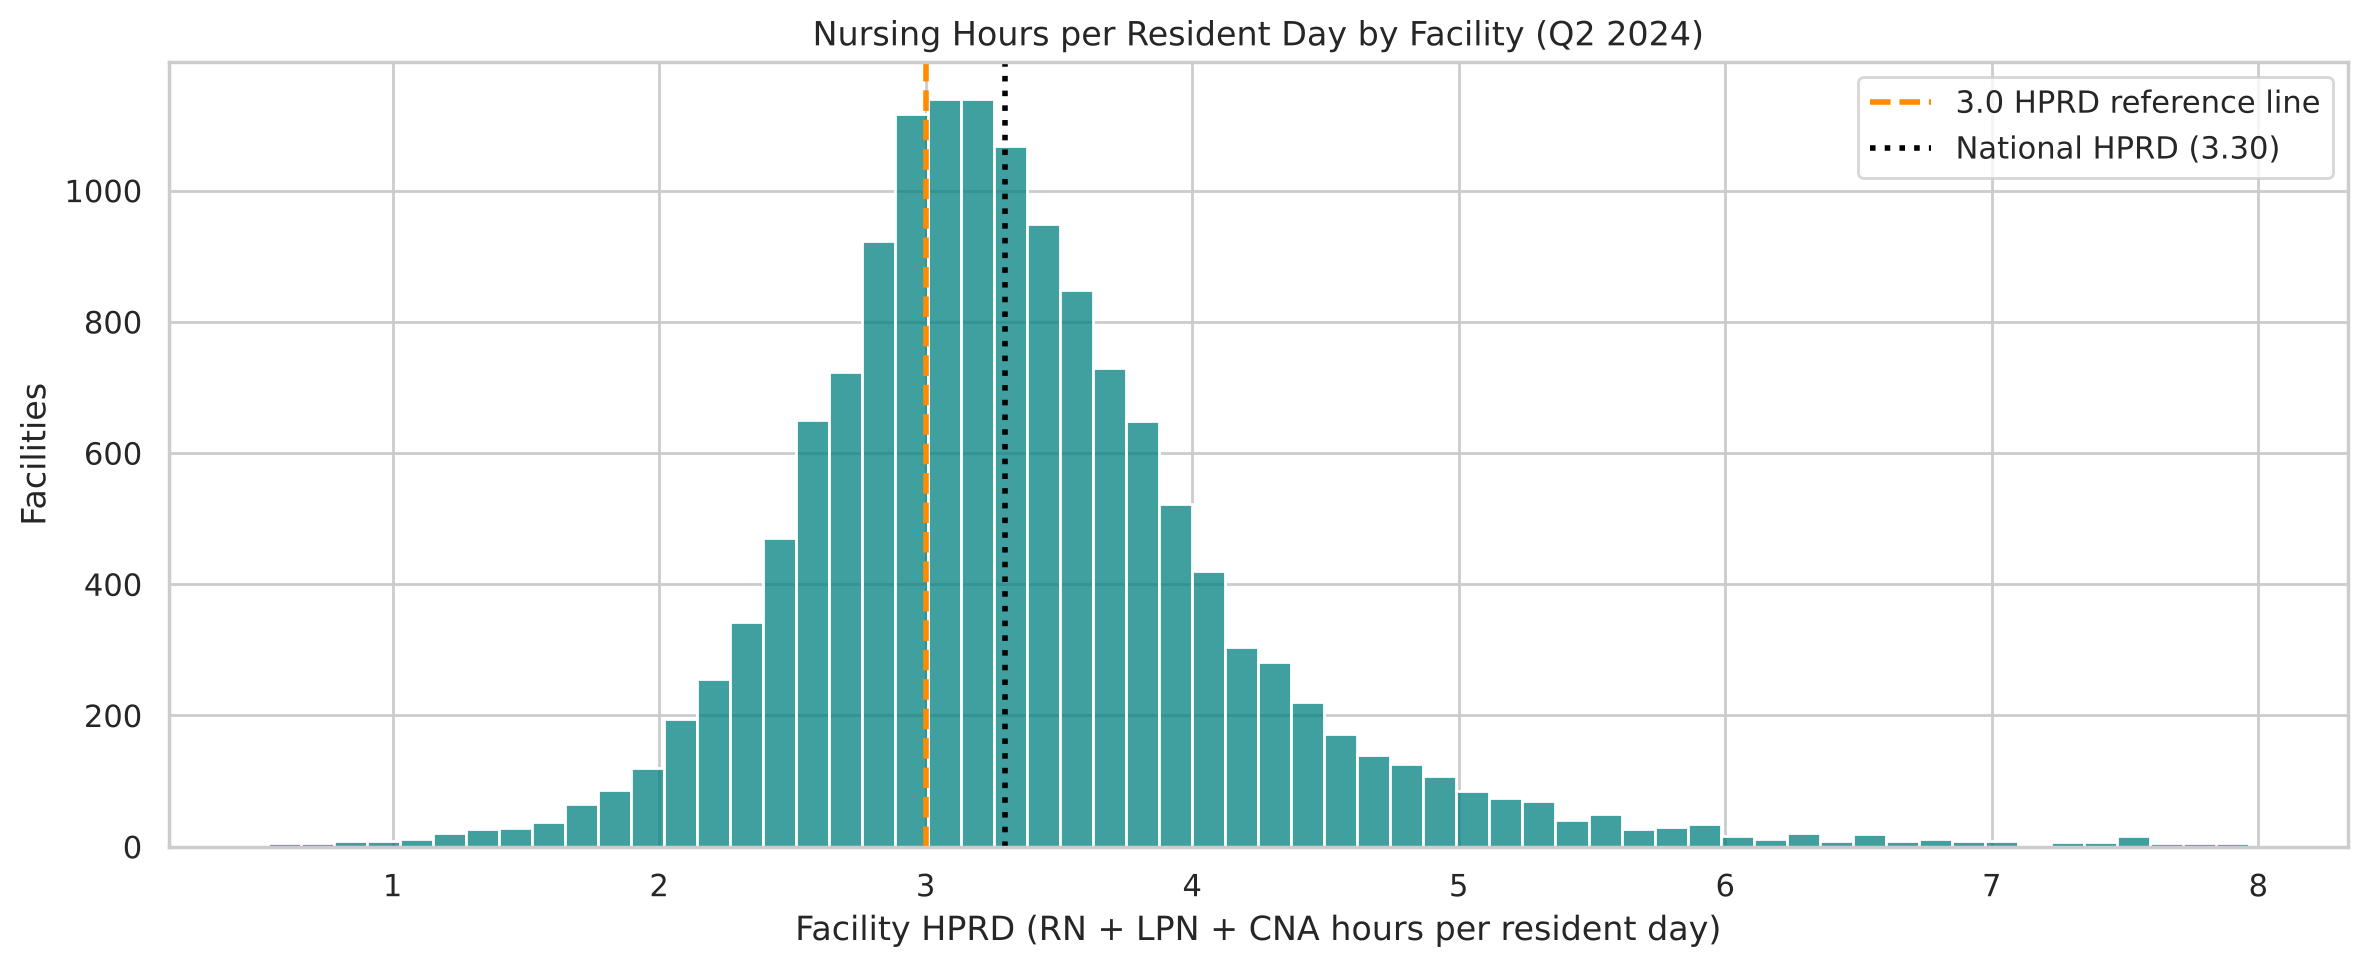

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(fv[fv["HPRD"] <= 8], x="HPRD", bins=60, color="teal", ax=ax)
ax.axvline(TARGET_HPRD, color="darkorange", ls="--", lw=2, label=f"{TARGET_HPRD} HPRD reference line")
ax.axvline(national, color="black", ls=":", lw=2, label=f"National HPRD ({national:.2f})")
ax.set(title="Nursing Hours per Resident Day by Facility (Q2 2024)",
       xlabel="Facility HPRD (RN + LPN + CNA hours per resident day)", ylabel="Facilities")
ax.legend()
plt.tight_layout()
plt.show()

**Findings**
- The national HPRD is **3.30** (weighted). The simple average of daily ratios is 3.37; the difference comes from small facilities, which tend to have higher ratios and get over-counted in a simple average.
- The typical facility sits between **2.84 and 3.74** (middle 50%), with a median of 3.25.
- **34.5% of facilities averaged below 3.0** for the quarter. The 3.0 line is a reference point for this analysis, not a regulatory requirement.
- The long right tail (above 6) is mostly very small facilities, where fixed staffing spread over a handful of residents produces high ratios.

---
## 5. Metric 2: Total nurse hours per facility per month

Facility-month records: 43,625
count    43625.0
mean      8347.0
std       5296.0
min          0.0
25%       4849.0
50%       7272.0
75%      10473.0
max      68462.0
Name: Monthly_Nurse_Hours, dtype: float64


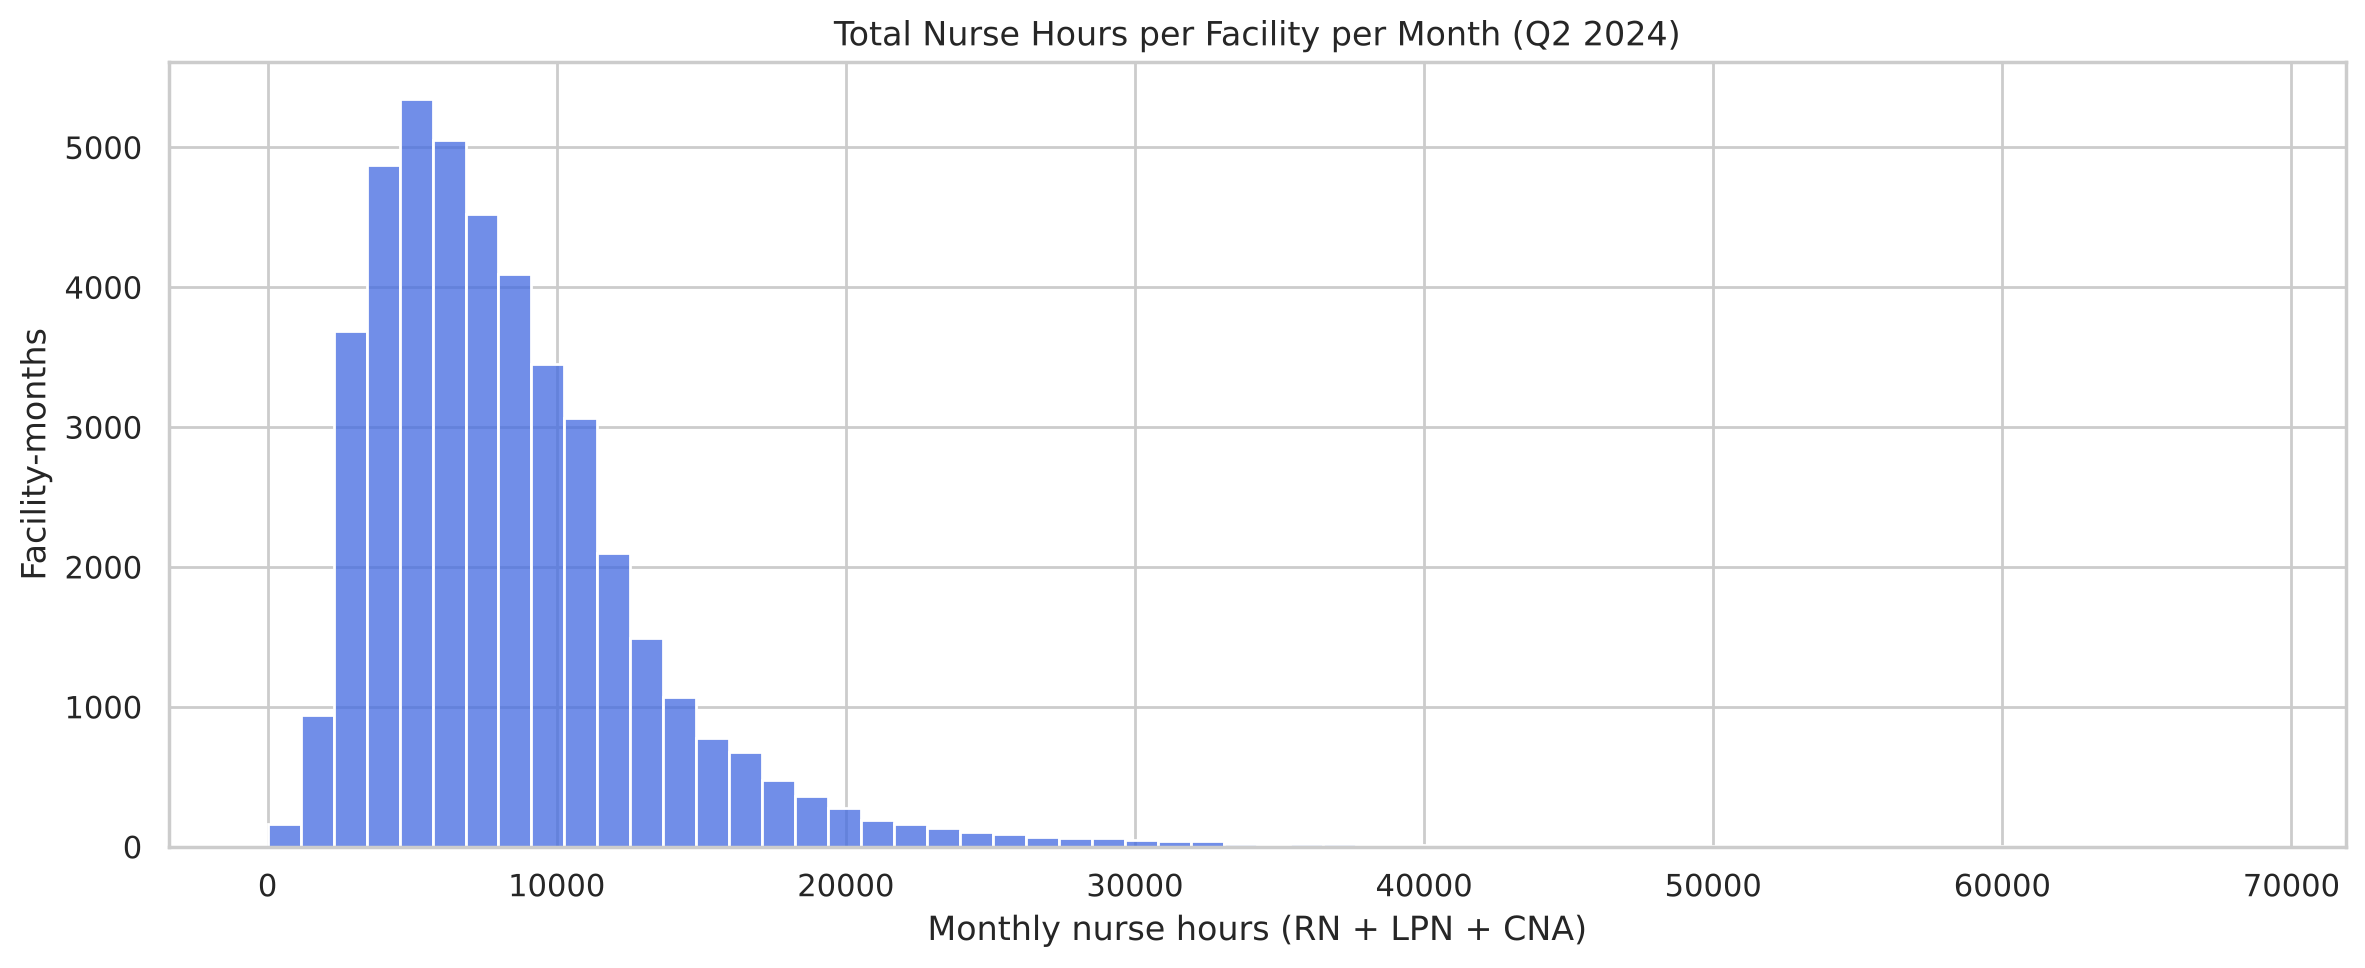


Monthly totals, five largest states (millions of hours):
Year_Month  2024-04  2024-05  2024-06
STATE                                
CA            11.79    12.19    11.77
NY             9.91    10.30     9.84
FL             7.75     7.99     7.74
TX             6.83     7.12     6.91
PA             6.67     6.91     6.62


In [ ]:
# Group by PROVNUM, not PROVNAME: some facility names belong to more than one provider
monthly = (dv.groupby(["PROVNUM", "PROVNAME", "STATE", "Year_Month"])["Total_Nurse_Hours"]
             .sum().reset_index(name="Monthly_Nurse_Hours"))
print(f"Facility-month records: {len(monthly):,}")
print(monthly["Monthly_Nurse_Hours"].describe().round(0))

fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(monthly, x="Monthly_Nurse_Hours", bins=60, color="royalblue", ax=ax)
ax.set(title="Total Nurse Hours per Facility per Month (Q2 2024)",
       xlabel="Monthly nurse hours (RN + LPN + CNA)", ylabel="Facility-months")
plt.tight_layout()
plt.show()

state_month = dv.groupby(["STATE", "Year_Month"])["Total_Nurse_Hours"].sum().unstack()
print("\nMonthly totals, five largest states (millions of hours):")
print((state_month.loc[state_month.sum(axis=1).nlargest(5).index] / 1e6).round(2))

**Findings**
- 43,625 facility-months. A typical facility logs about **7,300 nursing hours a month** (median), with the middle 50% between roughly 4,800 and 10,500.
- The distribution is right-skewed: a small number of very large New York facilities exceed 60,000 hours a month.
- **Staffing was stable across the quarter.** State totals rise slightly in May (which has 31 days vs. 30) and return to April levels in June.
- **Overtime:** the brief asks about overtime trends, but PBJ data records hours worked, not regular vs. overtime pay, so overtime can't be measured from this dataset.

---
## 6. Metric 3: Contract vs. employed staff
Formula: contract nurse hours ÷ total nurse hours

In [ ]:
national_contract = fv["contract_hrs"].sum() / fv["nurse_hrs"].sum()
print(f"Contract share of all nursing hours: {national_contract:.1%}")
print(f"Facilities with zero contract hours all quarter: {(fv['contract_hrs'] == 0).mean():.1%}")
print(f"Facilities where contract staff provide 25%+ of hours: {(fv['Contract_Share'] >= 0.25).mean():.1%}")
print("\nFacility contract share distribution:")
print(fv["Contract_Share"].describe().round(3))

Contract share of all nursing hours: 7.7%
Facilities with zero contract hours all quarter: 43.6%
Facilities where contract staff provide 25%+ of hours: 9.1%

Facility contract share distribution:
count    14544.000
mean         0.072
std          0.122
min          0.000
25%          0.000
50%          0.007
75%          0.098
max          1.000
Name: Contract_Share, dtype: float64


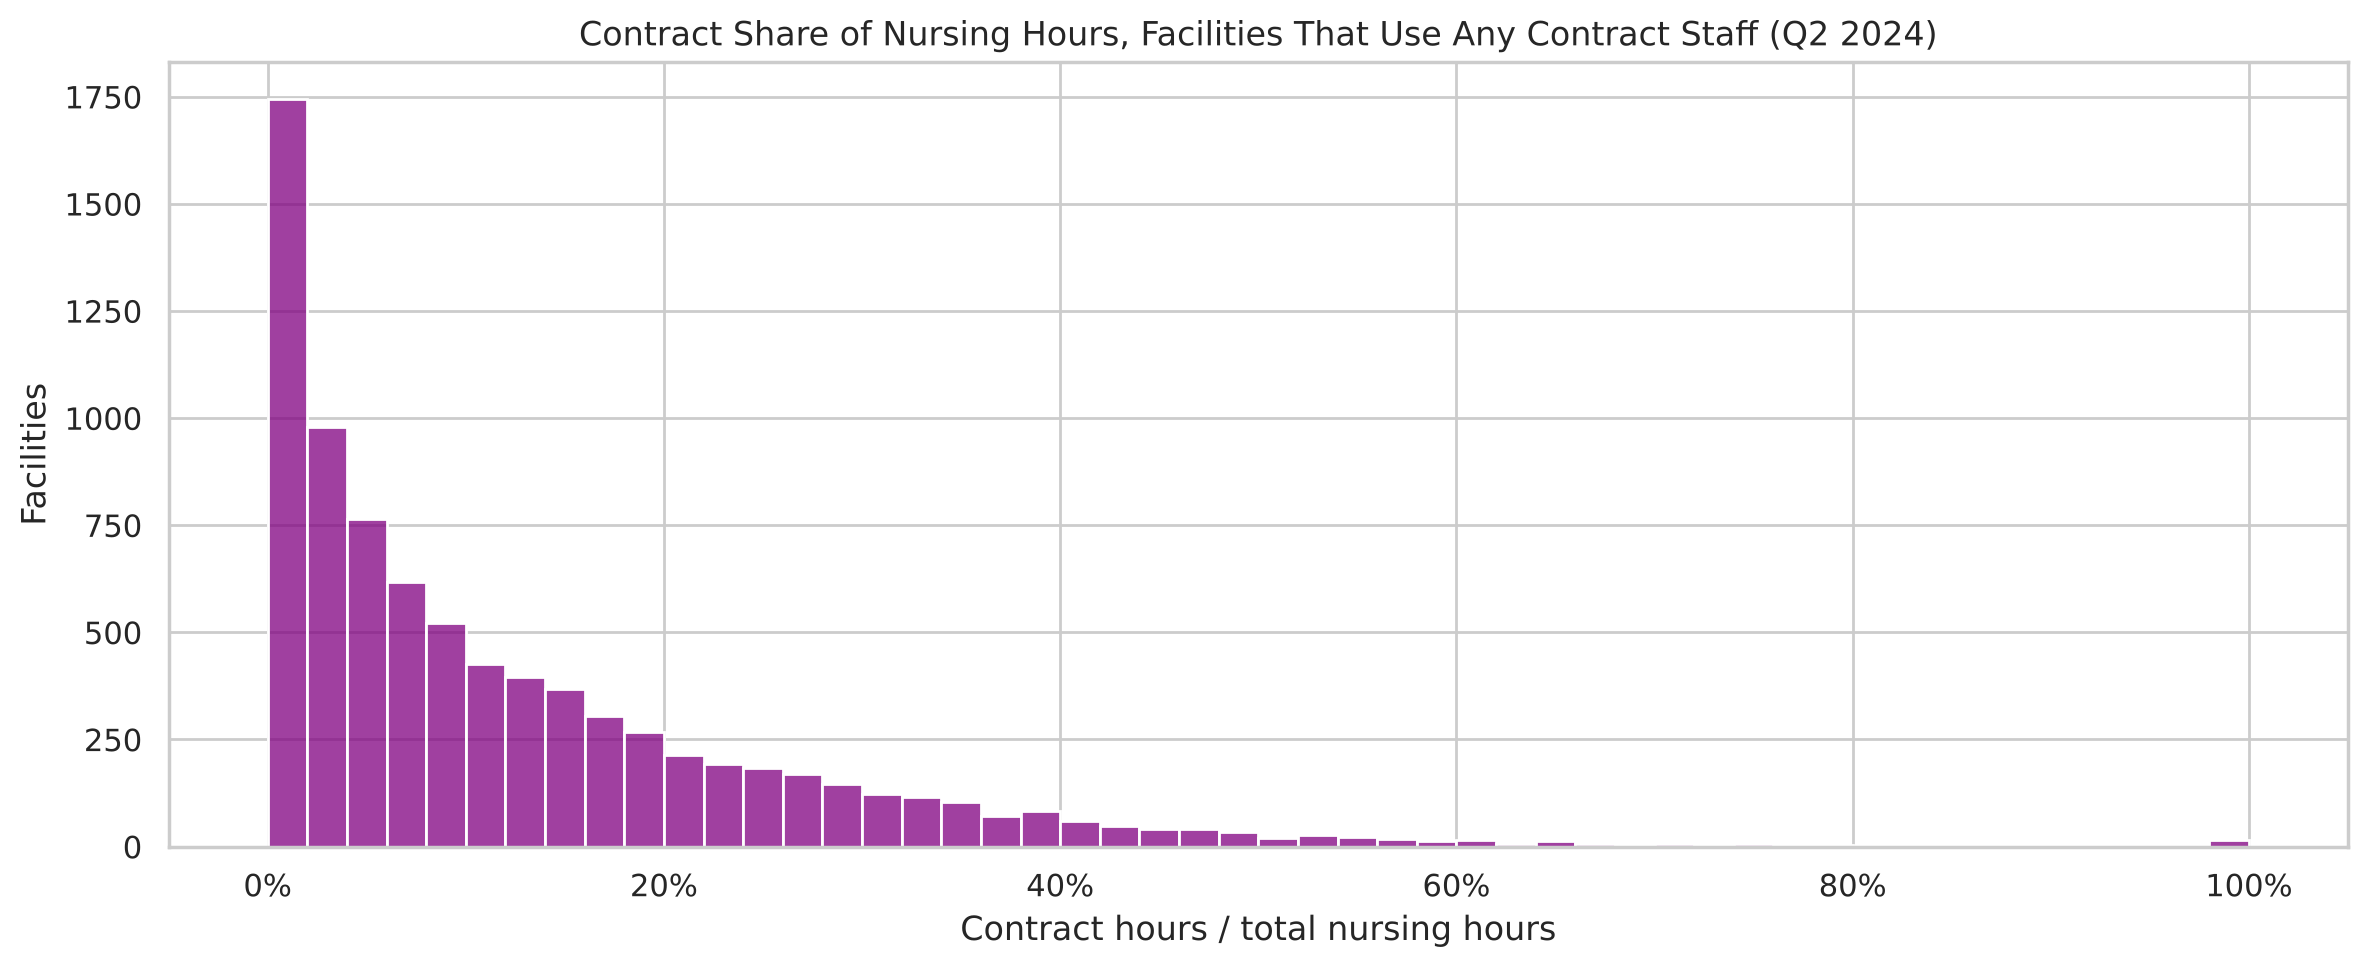

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(fv[fv["Contract_Share"] > 0], x="Contract_Share", bins=50, color="purple", ax=ax)
ax.set(title="Contract Share of Nursing Hours, Facilities That Use Any Contract Staff (Q2 2024)",
       xlabel="Contract hours / total nursing hours", ylabel="Facilities")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

**Findings**
- Contract (agency) staff provide **7.7% of all nursing hours** nationally.
- **43.6% of facilities used no contract staff at all** during the quarter, and the median facility's share is under 1%.
- Reliance is concentrated: **9.1% of facilities** got a quarter or more of their nursing hours from contract staff.
- The chart above shows only facilities that use *any* contract staff; including the zeros would hide everything behind one bar.

---
## 7. Metric 4: Average resident census

Highest average census per facility:
       facilities  avg_census
STATE                        
NY            596       163.4
DC             17       119.8
NJ            344       117.5
FL            690       106.1
MD            214       105.5

Lowest average census per facility:
       facilities  avg_census
STATE                        
SD             94        51.0
IA            393        50.3
KS            298        49.6
AK             14        45.5
PR              6        21.6


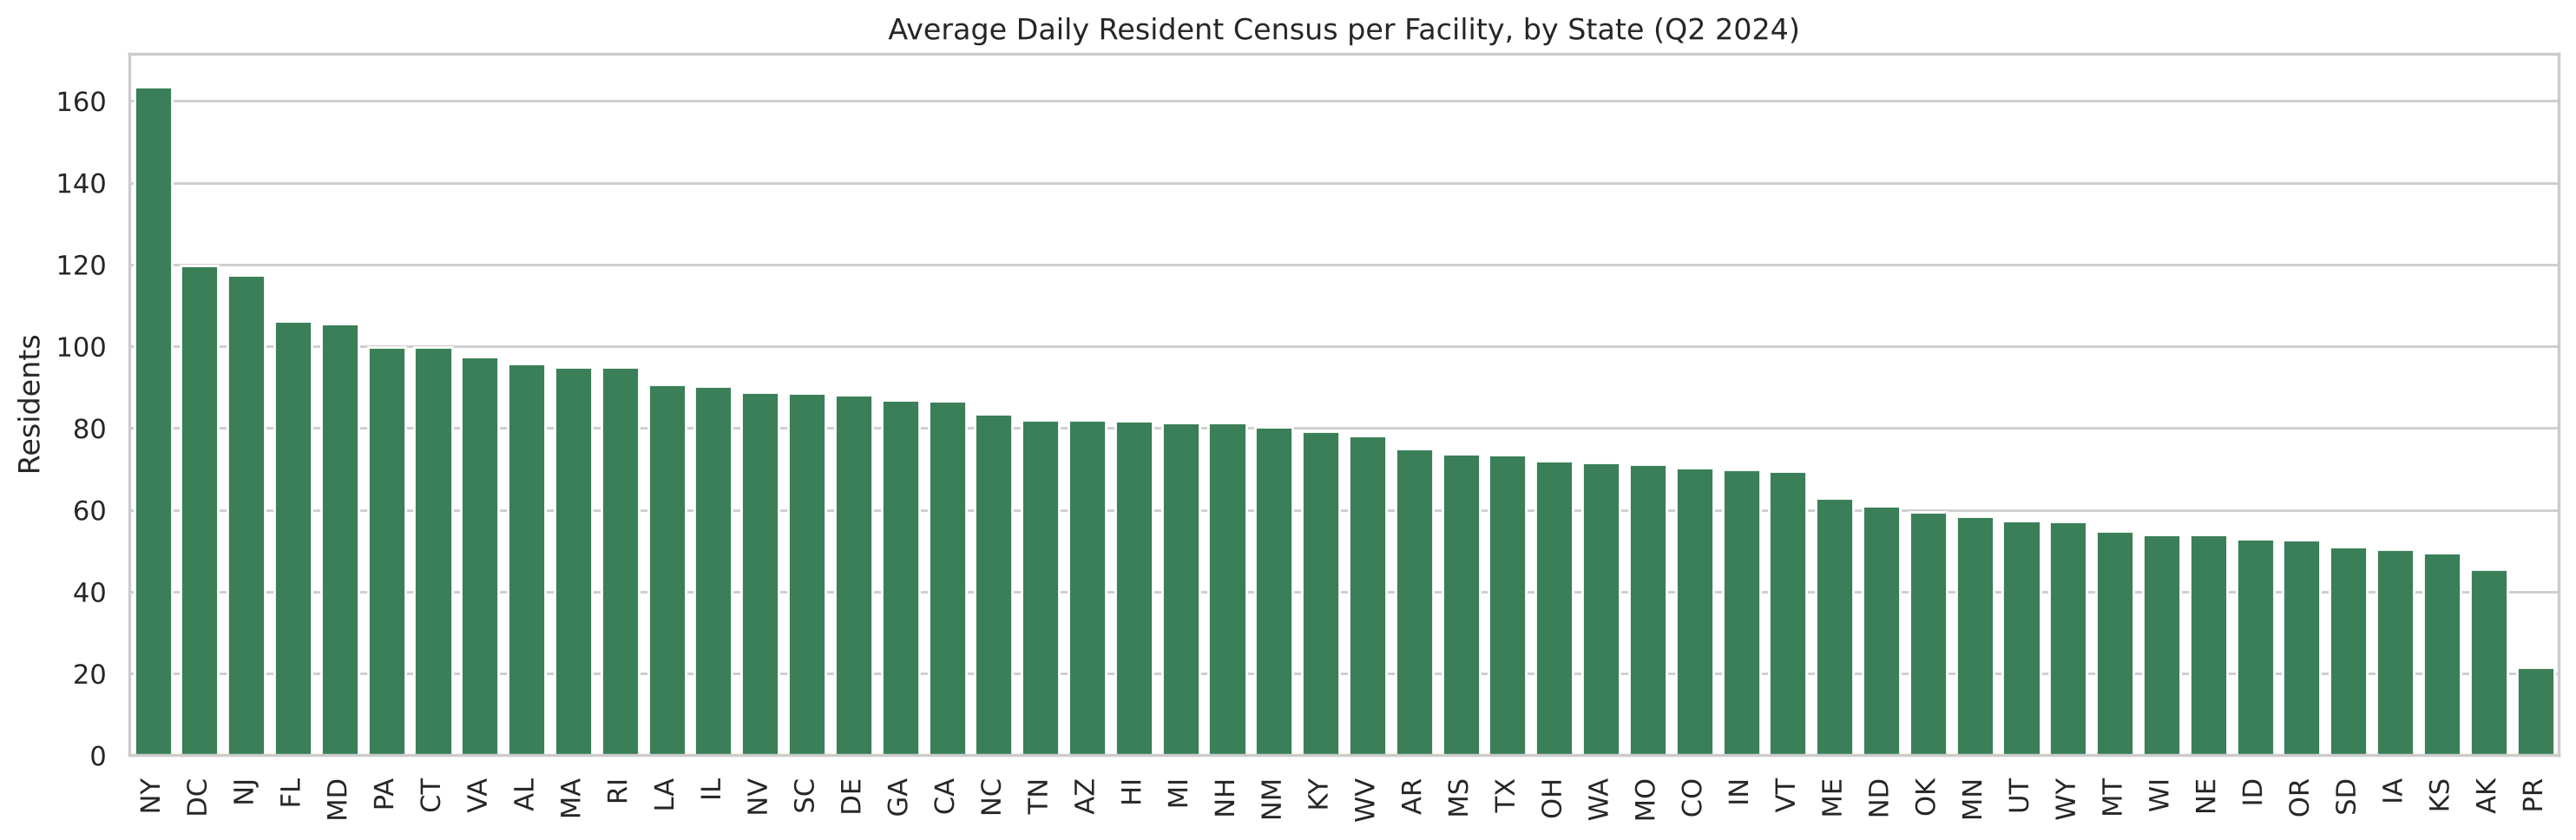

In [ ]:
state_census = (fv.groupby("STATE")
                  .agg(facilities=("PROVNUM", "count"), avg_census=("avg_census", "mean"))
                  .sort_values("avg_census", ascending=False))
print("Highest average census per facility:")
print(state_census.head(5).round(1))
print("\nLowest average census per facility:")
print(state_census.tail(5).round(1))

fig, ax = plt.subplots(figsize=(15, 5))
sns.barplot(x=state_census.index, y=state_census["avg_census"], color="seagreen", ax=ax)
ax.set(title="Average Daily Resident Census per Facility, by State (Q2 2024)", xlabel="", ylabel="Residents")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Findings**
- **New York facilities are by far the largest**, averaging 163 residents, followed by DC, New Jersey, Florida and Maryland (105–120).
- The smallest averages are in the Plains states (South Dakota, Iowa, Kansas, about 50), Alaska (46) and Puerto Rico (22, only 6 facilities).
- Facility size matters for interpretation: small facilities need minimum staffing regardless of census, which pushes their HPRD up (see section 9).

---
## 8. Metric 5: Facilities with the highest staffing hours

In [ ]:
cols = ["PROVNAME", "CITY", "STATE", "avg_census", "nurse_hrs", "HPRD"]
print("Top 10 facilities by total nursing hours (Q2 2024):")
display(fv.nlargest(10, "nurse_hrs")[cols].round(2))

print("Lowest totals among ALL facilities - note how many are reporting gaps, not small homes:")
low = fac.nsmallest(10, "nurse_hrs")[cols + ["Reporting_Gap"]].round(2)
display(low)

Top 10 facilities by total nursing hours (Q2 2024):


,PROVNAME,CITY,STATE,avg_census,nurse_hrs,HPRD
8143,ISABELLA GERIATRIC CENTER INC,NEW YORK,NY,683.18,199144.72,3.20
8121,COLER REHABILITATION AND NURSING CARE CENTER,ROOSEVELT ISLAND,NY,463.00,189810.35,4.51
8512,KINGS HARBOR MULTICARE CENTER,BRONX,NY,630.32,188650.15,3.29
8377,THE PLAZA REHAB AND NURSING CENTER,BRONX,NY,732.26,184704.83,2.77
8433,"RUTLAND NURSING HOME, INC",BROOKLYN,NY,448.92,183568.98,4.49
10722,CEDARBROOK SENIOR CARE AND REHABILITATION,ALLENTOWN,PA,515.76,168048.55,3.58
8383,BORO PARK CENTER FOR REHABILITATION AND HEALTH...,BROOKLYN,NY,478.91,165315.25,3.79
8444,COLD SPRING HILLS CENTER FOR NURSING AND REHAB,WOODBURY,NY,391.81,163375.07,4.58
8157,LORETTO HEALTH AND REHABILITATION CENTER,SYRACUSE,NY,551.35,161609.35,3.22
8528,TERENCE CARDINAL COOKE HEALTH CARE CENTER,NEW YORK,NY,523.19,161061.96,3.38


Lowest totals among ALL facilities - note how many are reporting gaps, not small homes:


,PROVNAME,CITY,STATE,avg_census,nurse_hrs,HPRD,Reporting_Gap
527,WHITE RIVER HEALTHCARE,CALICO ROCK,AR,43.52,0.00,0.00,True
7981,ST CATHERINE OF SIENA,CALDWELL,NJ,26.52,0.00,0.00,True
5577,BEAR MOUNTAIN AT WORCESTER,WORCESTER,MA,134.18,42.75,0.00,True
1268,LINCOLN HEALTH CARE CENTER,HUGO,CO,15.76,49.00,0.03,True
9045,CYPRESS GLEN RETIREMENT COMMUNITY,GREENVILLE,NC,2.58,351.24,2.72,False
6215,IRON RIVER CARE CENTER,IRON RIVER,MI,56.70,450.00,0.09,True
6039,CASS COUNTY MEDICAL CARE FACIL,CASSOPOLIS,MI,73.42,453.50,0.07,True
9066,THE FOREST AT DUKE INC,DURHAM,NC,3.19,460.25,1.59,False
5300,HERITAGE REHAB & LIVING CTR,WINTHROP,ME,3.30,534.97,1.78,False
7302,"SYLVIA G THOMPSON RESIDENCE CENTER, INC",SEDALIA,MO,117.59,542.00,0.05,True


**Findings**
- **Nine of the ten largest facilities by nursing hours are in New York**, led by Isabella Geriatric Center (199,145 hours, 683 residents). Cedarbrook Senior Care in Allentown, PA is the only one outside New York.
- High total hours reflect size, not generous staffing: their HPRD ranges from 2.77 (The Plaza, Bronx) to 4.58.
- **Correction to an earlier draft:** the earlier version reported "Miller's Merry Manor (IN)" as the single busiest facility. That came from grouping by facility *name*. A dozen separate Indiana facilities share that name; the largest one logged about 28,700 hours.
- **The lowest totals are mostly reporting gaps, not "micro-facilities."** Bear Mountain at Worcester averaged 134 residents. The genuinely small facilities at the bottom (e.g. Cypress Glen, NC, with fewer than 3 residents) are typically retirement communities with a tiny licensed nursing unit.

---
## 9. Analytical questions
### Q1. What is the relationship between staffing and resident census?

Daily census vs. total nurse hours:          r = 0.91
Facility census vs. HPRD (hours per resident): r = -0.12


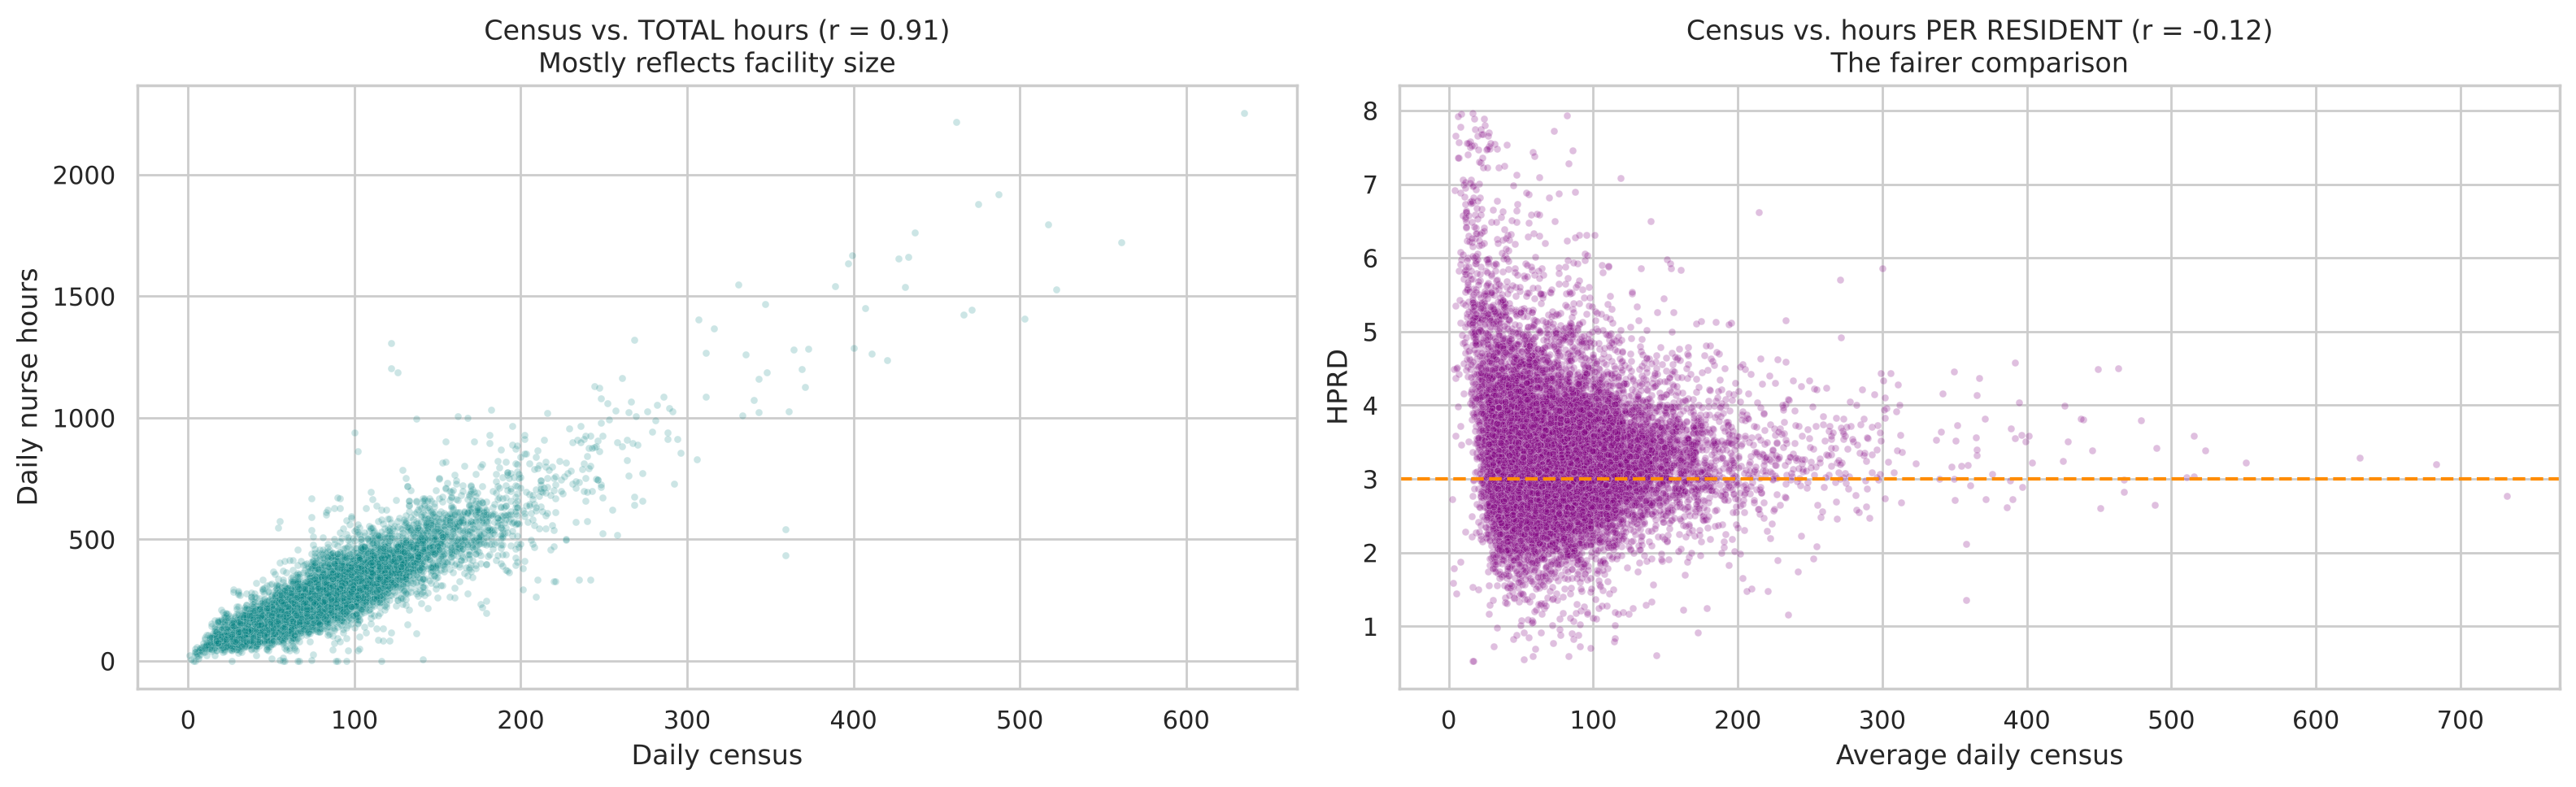

,facilities,median_census,HPRD,share_below_target
Size_Band,,,,
Small (Q1),3636.0,37.76,3.52,0.31
Mid-small (Q2),3636.0,62.60,3.25,0.40
Mid-large (Q3),3639.0,89.09,3.25,0.36
Large (Q4),3633.0,127.88,3.29,0.31


In [ ]:
r_total = dv["MDScensus"].corr(dv["Total_Nurse_Hours"])
r_hprd = fv["avg_census"].corr(fv["HPRD"])
print(f"Daily census vs. total nurse hours:          r = {r_total:.2f}")
print(f"Facility census vs. HPRD (hours per resident): r = {r_hprd:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sample = dv.sample(10000, random_state=42)
sns.scatterplot(sample, x="MDScensus", y="Total_Nurse_Hours", alpha=0.2, s=10, color="teal", ax=axes[0])
axes[0].set(title=f"Census vs. TOTAL hours (r = {r_total:.2f})\nMostly reflects facility size",
            xlabel="Daily census", ylabel="Daily nurse hours")
sns.scatterplot(fv[fv["HPRD"] <= 8], x="avg_census", y="HPRD", alpha=0.25, s=10, color="purple", ax=axes[1])
axes[1].axhline(TARGET_HPRD, color="darkorange", ls="--")
axes[1].set(title=f"Census vs. hours PER RESIDENT (r = {r_hprd:.2f})\nThe fairer comparison",
            xlabel="Average daily census", ylabel="HPRD")
plt.tight_layout()
plt.show()

fv["Size_Band"] = pd.qcut(fv["avg_census"], 4, labels=["Small (Q1)", "Mid-small (Q2)", "Mid-large (Q3)", "Large (Q4)"])
bands = fv.groupby("Size_Band", observed=True).apply(
    lambda g: pd.Series({"facilities": len(g), "median_census": g["avg_census"].median(),
                         "HPRD": weighted_hprd(g), "share_below_target": (g["HPRD"] < TARGET_HPRD).mean()}),
    include_groups=False)
bands.round(2)

**Findings**
- Daily census and *total* nurse hours correlate strongly (**r = 0.91**), but that mostly says that bigger facilities employ more nurses. It doesn't show that staffing adjusts day to day.
- The fairer test compares census with hours **per resident**: **r = −0.12**. Facility size barely predicts how much nursing time each resident receives, and if anything larger facilities provide slightly less.
- By size band, the smallest quarter of facilities provides the most care per resident (**3.52 HPRD**). The other three bands are nearly identical (3.25–3.29), and the mid-small band has the highest share below 3.0 (40%).

### Q2. Which facilities have the highest staffing hours?
See section 8: nine of the top ten are large New York facilities.

### Q3. What are the average staffing levels by state?

Highest HPRD (states with 10+ facilities):
STATE  facilities  HPRD  share_below_target
   AK          14  5.41                0.00
   OR         121  4.19                0.02
   ND          68  4.08                0.09
   HI          40  3.99                0.02
   CA        1142  3.97                0.03

Lowest HPRD (states with 10+ facilities):
STATE  facilities  HPRD  share_below_target
   NM          66  2.84                0.70
   IN         509  2.82                0.69
   OK         273  2.80                0.68
   TX        1167  2.68                0.77
   MO         472  2.42                0.79

States/territories below 3.0: 5 of 52


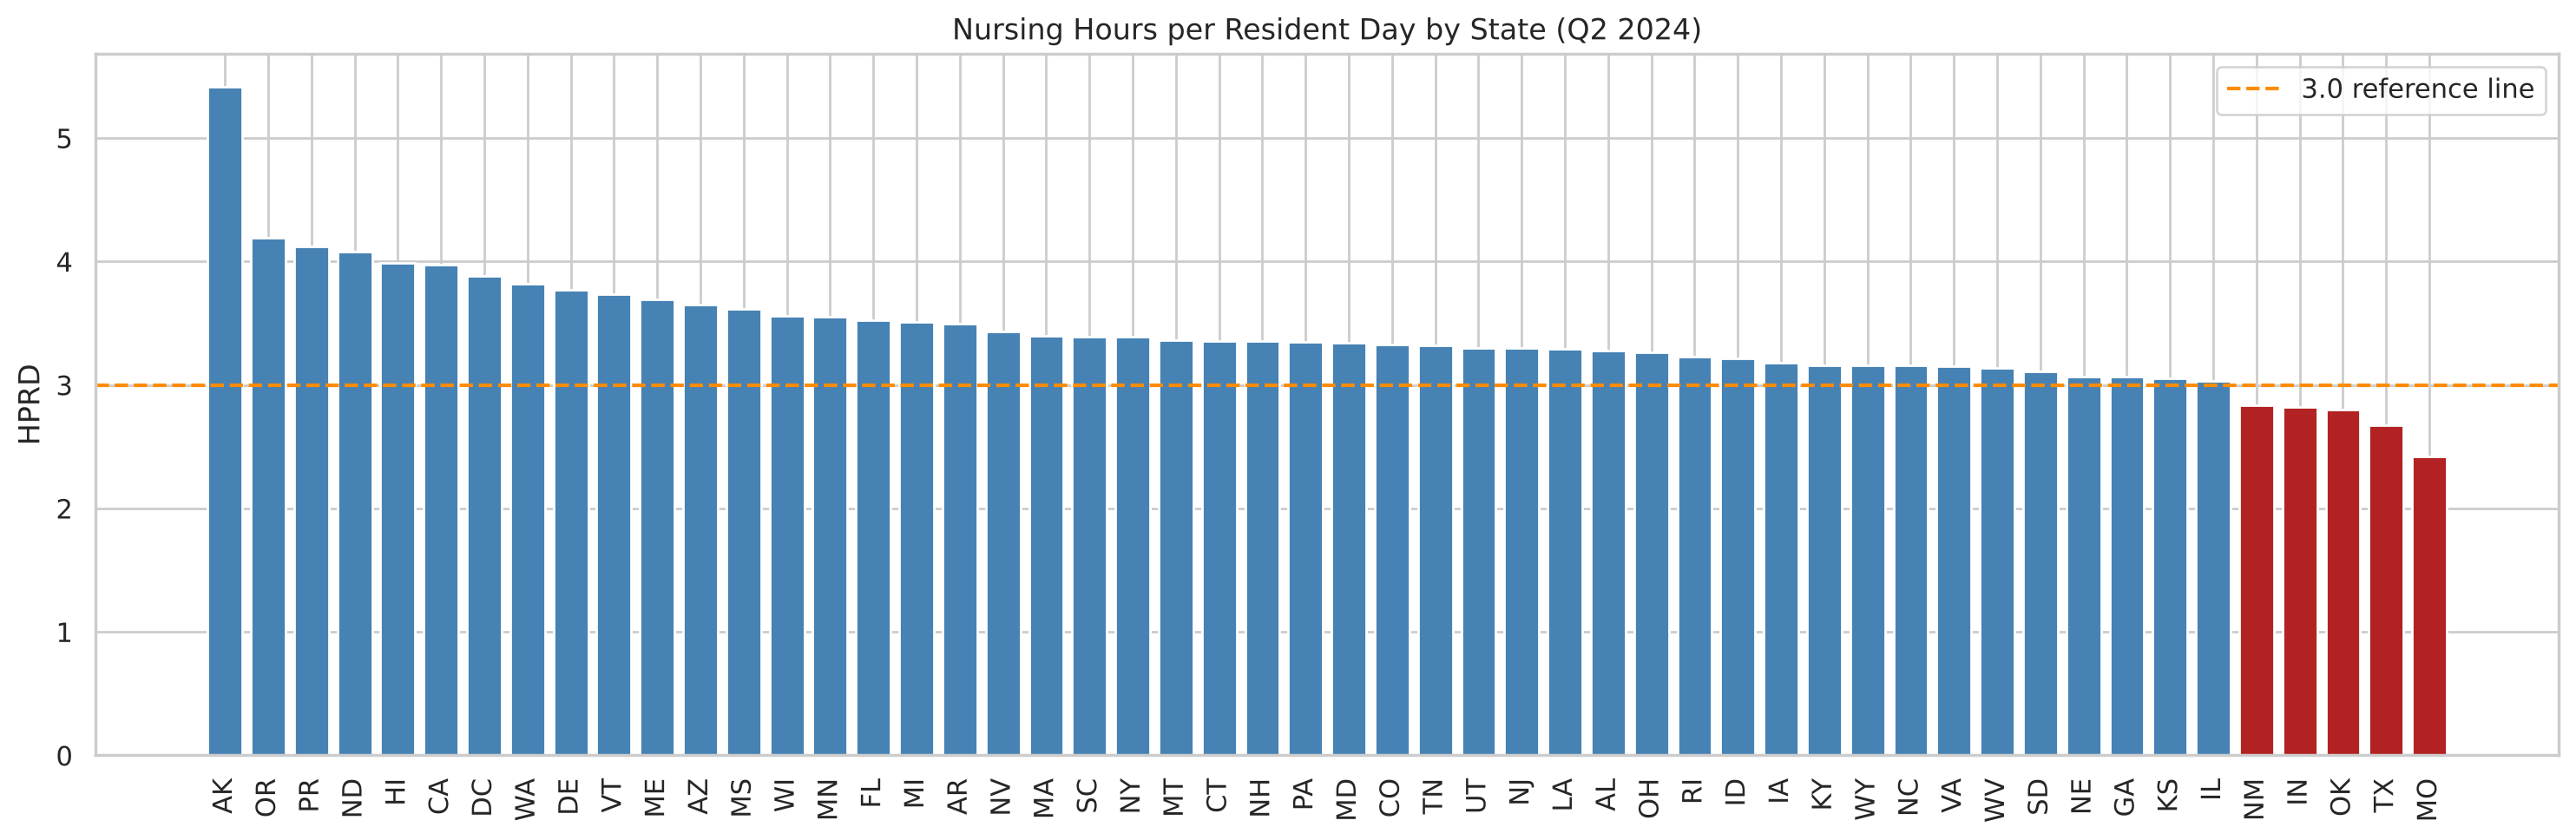

In [ ]:
state = (fv.groupby("STATE")
           .agg(facilities=("PROVNUM", "count"), nurse_hrs=("nurse_hrs", "sum"),
                resident_days=("resident_days", "sum"), contract_hrs=("contract_hrs", "sum"),
                share_below_target=("HPRD", lambda s: (s < TARGET_HPRD).mean()))
           .reset_index())
state["HPRD"] = state["nurse_hrs"] / state["resident_days"]
state["Contract_Share"] = state["contract_hrs"] / state["nurse_hrs"]
state = state.sort_values("HPRD", ascending=False)

big = state[state["facilities"] >= 10]
show = ["STATE", "facilities", "HPRD", "share_below_target"]
print("Highest HPRD (states with 10+ facilities):")
print(big.head(5)[show].round(2).to_string(index=False))
print("\nLowest HPRD (states with 10+ facilities):")
print(big.tail(5)[show].round(2).to_string(index=False))
print(f"\nStates/territories below {TARGET_HPRD}: {(state['HPRD'] < TARGET_HPRD).sum()} of {len(state)}")

fig, ax = plt.subplots(figsize=(15, 5))
colors = ["firebrick" if h < TARGET_HPRD else "steelblue" for h in state["HPRD"]]
ax.bar(state["STATE"], state["HPRD"], color=colors)
ax.axhline(TARGET_HPRD, color="darkorange", ls="--", label=f"{TARGET_HPRD} reference line")
ax.set(title="Nursing Hours per Resident Day by State (Q2 2024)", ylabel="HPRD")
ax.legend()
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Findings**
- **Five states fall below 3.0 HPRD: Missouri (2.42), Texas (2.68), Oklahoma (2.80), Indiana (2.82) and New Mexico (2.84).** In each, 68–79% of facilities are below 3.0, so the shortfall is systemic, not a few outliers.
- **Texas stands out for scale**: 1,167 facilities, 77% of them below 3.0. Texas was missing entirely from the earlier Excel-based draft.
- **The highest-staffed states** (10+ facilities) are Alaska (5.41), Oregon (4.19), North Dakota (4.08), Hawaii (3.99) and California (3.97). Alaska has only 14 facilities, mostly small.
- An interactive state map is in the [dashboard](https://clipboard-health-staffing.streamlit.app/).

### Q4. Which facilities have the lowest staffing coverage?

In [ ]:
watch = fac[fac["low_days"] >= 10].copy()
watch["Flag"] = np.where(watch["Reporting_Gap"], "Likely reporting gap", "Possible strain")
print(f"Facilities with 10+ days below {STRAIN_HPRD} HPRD: {len(watch)}")
print(watch["Flag"].value_counts().to_string())

print("\nLowest-HPRD facilities with plausible reporting:")
display(fv.nsmallest(10, "HPRD")[["PROVNAME", "CITY", "STATE", "avg_census", "HPRD", "low_days"]].round(2))

Facilities with 10+ days below 1.5 HPRD: 381
Flag
Possible strain         361
Likely reporting gap     20

Lowest-HPRD facilities with plausible reporting:


,PROVNAME,CITY,STATE,avg_census,HPRD,low_days
13640,ELECTRA HEALTHCARE CENTER,ELECTRA,TX,16.78,0.53,73
10420,EAST CASCADE RETIREMENT COMMUNITY,MADRAS,OR,16.52,0.53,88
6620,MINNESOTA VETERANS HOME - SILVER BAY,SILVER BAY,MN,52.03,0.55,91
1575,"CURTIS HOME ST ELIZABETH CENTER, THE",MERIDEN,CT,57.93,0.60,91
12960,LASATA CARE CENTER,CEDARBURG,WI,82.92,0.60,91
3128,"PEARL OF ELK GROVE, THE",ELK GROVE VILLAGE,IL,143.81,0.61,91
7079,STONECREST HEALTHCARE,VIBURNUM,MO,59.66,0.70,68
2143,GUARDIAN CARE NURSING & REHABILITATION CENTER,ORLANDO,FL,98.09,0.71,91
6636,HAYES RESIDENCE,SAINT PAUL,MN,30.91,0.72,91
981,INFINITY CARE OF EAST LOS ANGELES,LOS ANGELES,CA,90.60,0.73,61


**Findings**
- **381 facilities** had 10 or more days below 1.5 HPRD during the quarter.
  - **20 are likely reporting gaps** (near-zero hours all quarter).
  - **361 are possible strain** and warrant follow-up.
- Several of the lowest-HPRD facilities with "plausible" reporting (around 0.5–0.75 HPRD, below 1.5 on most days) may also be partial reporting problems. Care at that level isn't realistic, so these should be verified against CMS star ratings or inspection data before drawing conclusions.
- The dashboard's **Census & Capacity** tab includes a filterable version of this watchlist.

### Q5. Do certain states rely more on contract nurses?

Highest contract share:
STATE  facilities  Contract_Share  HPRD
   VT          33           0.320 3.737
   ME          81           0.182 3.693
   NH          71           0.171 3.356
   PA         663           0.154 3.351
   NJ         344           0.151 3.297

Lowest contract share:
STATE  facilities  Contract_Share  HPRD
   NV          66           0.030 3.431
   FL         690           0.028 3.524
   AR         215           0.022 3.496
   PR           6           0.019 4.122
   AL         222           0.016 3.278

Contract share vs. HPRD: r = 0.21 across states, r = 0.02 across facilities


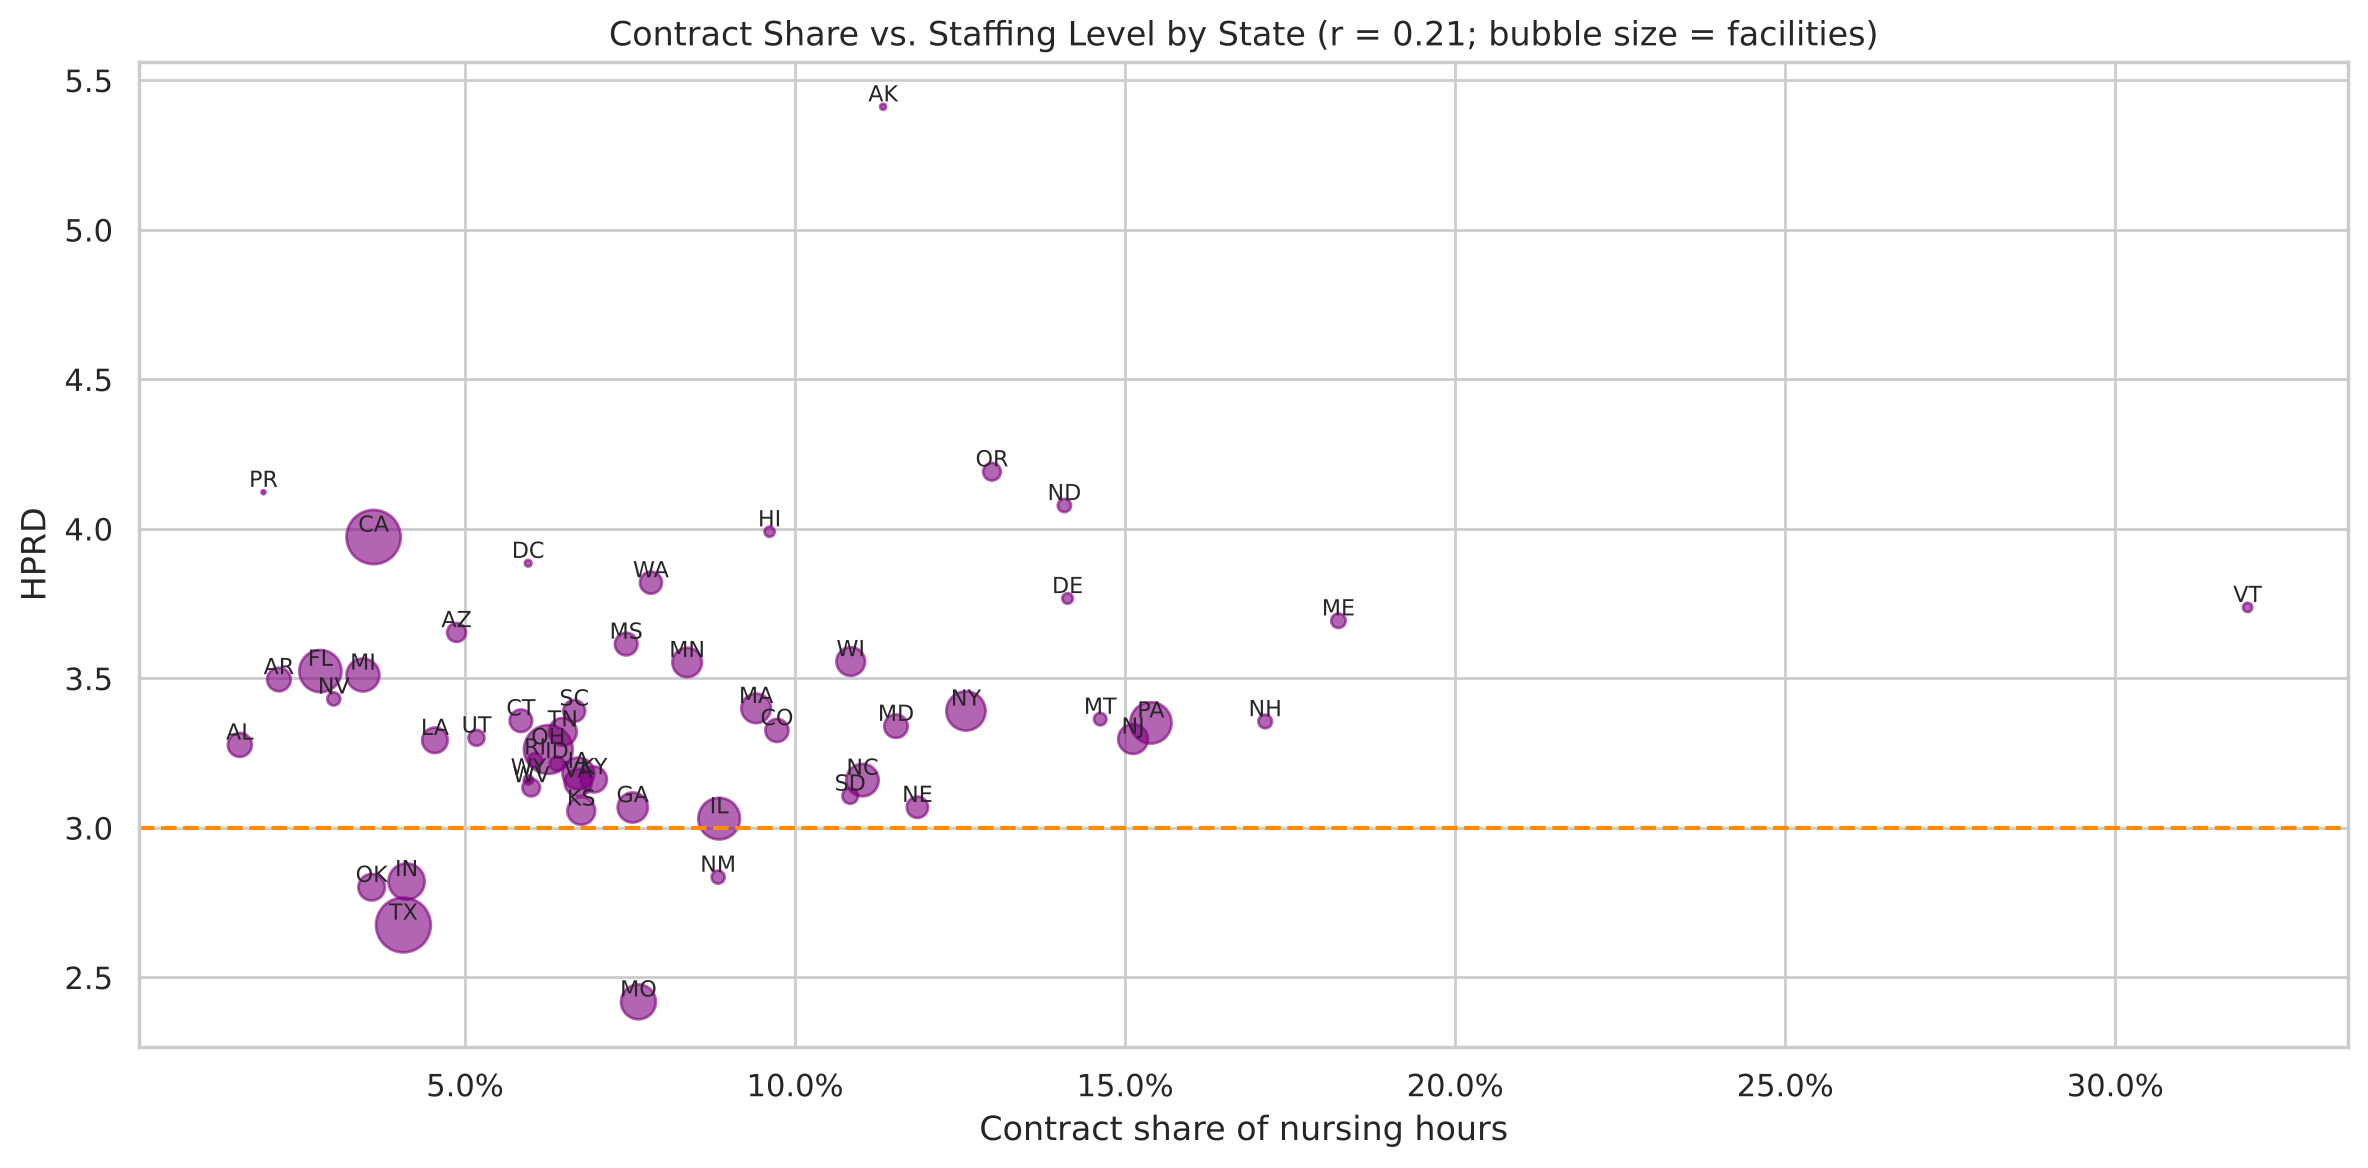

In [ ]:
by_contract = state.sort_values("Contract_Share", ascending=False)
print("Highest contract share:")
print(by_contract.head(5)[["STATE", "facilities", "Contract_Share", "HPRD"]].round(3).to_string(index=False))
print("\nLowest contract share:")
print(by_contract.tail(5)[["STATE", "facilities", "Contract_Share", "HPRD"]].round(3).to_string(index=False))

r_state = state["Contract_Share"].corr(state["HPRD"])
r_fac = fv["Contract_Share"].corr(fv["HPRD"])
print(f"\nContract share vs. HPRD: r = {r_state:.2f} across states, r = {r_fac:.2f} across facilities")

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(state["Contract_Share"], state["HPRD"], s=state["facilities"] / 3, alpha=0.6, color="purple")
for _, row in state.iterrows():
    ax.annotate(row["STATE"], (row["Contract_Share"], row["HPRD"]), fontsize=8, ha="center", va="bottom")
ax.axhline(TARGET_HPRD, color="darkorange", ls="--")
ax.set(title=f"Contract Share vs. Staffing Level by State (r = {r_state:.2f}; bubble size = facilities)",
       xlabel="Contract share of nursing hours", ylabel="HPRD")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

**Findings**
- **Yes, reliance varies widely. Vermont relies on contract staff far more than anywhere else (32% of nursing hours)**, followed by Maine (18%), New Hampshire (17%), Pennsylvania (15%) and New Jersey (15%). Vermont was also missing from the earlier Excel-based draft.
- **Alabama (1.6%), Arkansas, Florida and Nevada** use the least.
- **Contract use is only weakly associated with staffing levels**: r = 0.21 across states and 0.02 across facilities. Some high-contract states staff well (Vermont, Maine), but so do low-contract states (Florida, Arkansas). This data can't show whether contract staff *cause* higher staffing. An earlier draft described contract labor as a proven "safety valve"; the data doesn't support that claim.

---
## 10. Summary

| Question | Answer |
|---|---|
| Staffing vs. census | Total hours track census (r = 0.91) because of size; hours *per resident* barely relate to size (r = −0.12) |
| Highest staffing hours | Large New York facilities (9 of the top 10) |
| Staffing by state | National 3.30 HPRD; MO, TX, OK, IN and NM below 3.0 |
| Lowest coverage | 361 facilities with frequent days under 1.5 HPRD, plus 20 reporting gaps |
| Contract reliance | 7.7% of hours nationally; Vermont highest at 32%; weak link to staffing levels |

### Data quality lessons
1. **Excel exports can silently truncate data**: 21% of rows and eight states were lost before switching to the CSV.
2. **Facility names aren't IDs**: grouping by name merged a dozen facilities into one.
3. **Near-zero values are usually missing data**: 20 facilities were excluded as reporting gaps.
4. **Correlation needs the right denominator**: census vs. total hours (0.91) and census vs. hours per resident (−0.12) tell different stories.

### Next steps
- Join CMS star ratings and inspection data to connect staffing levels with quality outcomes
- Compare against other quarters to see whether the low-staffing states are improving
- Move the pipeline into Snowflake for scheduled quarterly refreshes

**Interactive dashboard:** [clipboard-health-staffing.streamlit.app](https://clipboard-health-staffing.streamlit.app/)